In [2]:
import pandas as pd
import matplotlib.pyplot as plt
#pandas helps load the dataset, handle missing values, manipulate teh columns etc
#matplotlib helps us create charts to visualize our findings

In [3]:
df = pd.read_csv("retail_store_sales.csv")
#df is a variable that stores the loaded csv file. we dont need to mention the path name as the file is located in the same folder

In [4]:
df.head()
#displays the first 5 rows by default

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [5]:
print("Dataset shape:" ,df.shape)
#returns (no. of rows, no. of columns)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()

Dataset shape: (12575, 11)

Column names:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.1+ M

In [6]:
df.isnull().sum()
#isnull() checks every cell and marks missing values as true 
#sum() counts missing values in each column because true counts as 1

Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

In [7]:
df.duplicated().sum()
#checks for duplicate rows

np.int64(0)

In [8]:
df.describe()
#for each numeric column it calculates count, mean, std, min, max and quartiles

,Price Per Unit,Quantity,Total Spent
count,11966.000000,11971.000000,11971.000000
mean,23.365912,5.536380,129.652577
std,10.743519,2.857883,94.750697
min,5.000000,1.000000,5.000000
25%,14.000000,3.000000,51.000000
50%,23.000000,6.000000,108.500000
75%,33.500000,8.000000,192.000000
max,41.000000,10.000000,410.000000


In [9]:
df["Transaction Date"].dtype

<StringDtype(storage='python', na_value=nan)>

In [10]:
df["Transaction Date"] = pd.to_datetime(df["Transaction Date"])
#to convert date-like strings into Pandas datetime values

In [11]:
df["Transaction Date"].dtype

dtype('<M8[us]')

In [12]:
df["Transaction Date"].head()

0   2024-04-08
1   2023-07-23
2   2022-10-05
3   2022-05-07
4   2022-10-02
Name: Transaction Date, dtype: datetime64[us]

In [13]:
missing_count = df.isnull().sum()

missing_percent = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
})

missing_summary[missing_summary["Missing Count"] > 0]
#to find the percentage of missing values in order to decide how to deal with them

,Missing Count,Missing Percentage
Item,1213,9.646123
Price Per Unit,609,4.842942
Quantity,604,4.803181
Total Spent,604,4.803181
Discount Applied,4199,33.391650


In [14]:
df[df["Item"].isnull()].head(10)
#inner df marks true for every null field and outer df displays the first 10 values of the dataset (which return true for null)

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,NaN
17,TXN_9634894,CUST_15,Milk Products,NaN,NaN,10.0,275.0,Digital Wallet,Online,2022-04-17,NaN
19,TXN_4206593,CUST_01,Furniture,NaN,35.0,NaN,NaN,Digital Wallet,Online,2025-01-13,False
21,TXN_8685338,CUST_15,Milk Products,NaN,NaN,3.0,105.0,Credit Card,In-store,2023-10-29,NaN
25,TXN_3481599,CUST_05,Furniture,NaN,39.5,NaN,NaN,Cash,Online,2022-09-08,False
32,TXN_1543244,CUST_20,Food,NaN,NaN,8.0,196.0,Credit Card,Online,2024-10-25,True
34,TXN_1621497,CUST_06,Patisserie,NaN,23.0,NaN,NaN,Cash,In-store,2023-02-18,NaN


In [15]:
df[df[["Price Per Unit", "Quantity", "Total Spent"]].isnull().any(axis=1)].head(10)
#to check if multiple columns have null at the same time so we can get rid of the particular tuple 

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,NaN
17,TXN_9634894,CUST_15,Milk Products,NaN,NaN,10.0,275.0,Digital Wallet,Online,2022-04-17,NaN
19,TXN_4206593,CUST_01,Furniture,NaN,35.0,NaN,NaN,Digital Wallet,Online,2025-01-13,False
21,TXN_8685338,CUST_15,Milk Products,NaN,NaN,3.0,105.0,Credit Card,In-store,2023-10-29,NaN
25,TXN_3481599,CUST_05,Furniture,NaN,39.5,NaN,NaN,Cash,Online,2022-09-08,False
32,TXN_1543244,CUST_20,Food,NaN,NaN,8.0,196.0,Credit Card,Online,2024-10-25,True
34,TXN_1621497,CUST_06,Patisserie,NaN,23.0,NaN,NaN,Cash,In-store,2023-02-18,NaN


In [16]:
df["Calculated Total"] = df["Price Per Unit"] * df["Quantity"]
df[["Price Per Unit", "Quantity", "Total Spent", "Calculated Total"]].head(10)
#to check whether the total matches price*quantity

,Price Per Unit,Quantity,Total Spent,Calculated Total
0,18.5,10.0,185.0,185.0
1,29.0,9.0,261.0,261.0
2,21.5,2.0,43.0,43.0
3,27.5,9.0,247.5,247.5
4,12.5,7.0,87.5,87.5
5,NaN,10.0,200.0,NaN
6,5.0,8.0,40.0,40.0
7,33.5,NaN,NaN,NaN
8,27.5,1.0,27.5,27.5
9,36.5,3.0,109.5,109.5


In [18]:
#the analysis henceforth is carried out by the assumption that ppu is the discounted price
valid_totals = df.dropna(
    subset=["Price Per Unit", "Quantity", "Total Spent"]
).copy()

valid_totals["Calculated Total"] = (
    valid_totals["Price Per Unit"] * valid_totals["Quantity"]
)

mismatch = (
    valid_totals["Total Spent"] - valid_totals["Calculated Total"]
).abs() > 0.01

print("Complete transactions:", len(valid_totals))
print("Mismatched totals:", mismatch.sum())

#first we checked if the calculated total (by creating a copy of the df and evaluating price*qty) matches the given total
#in case it does we calculate mismatch. If it exceeds 0.01 it is marked as true (ie 1) and sum() finds no. of columns having the mismatch

Complete transactions: 11362
Mismatched totals: 0


In [19]:
print(
    "Rows missing both:",
    (df["Quantity"].isnull() & df["Total Spent"].isnull()).sum()
)

print(
    "Rows missing quantity only:",
    (df["Quantity"].isnull() & df["Total Spent"].notnull()).sum()
)

print(
    "Rows missing total only:",
    (df["Quantity"].notnull() & df["Total Spent"].isnull()).sum()
)
#to check is the values are missing in the exact same rows

Rows missing both: 604
Rows missing quantity only: 0
Rows missing total only: 0


In [21]:
df_clean = df.dropna(
    subset=["Quantity", "Total Spent"]
).copy()

print("Original rows:", len(df))
print("Rows after removing incomplete sales:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

#creating a copy of df by eliminating the rows which contain null values for both, quantity and total spent

Original rows: 12575
Rows after removing incomplete sales: 11971
Rows removed: 604


In [22]:
df_clean[df_clean["Price Per Unit"].isnull()][
    ["Item", "Quantity", "Price Per Unit", "Total Spent"]
].head(10) 

,Item,Quantity,Price Per Unit,Total Spent
5,NaN,10.0,NaN,200.0
11,NaN,8.0,NaN,52.0
17,NaN,10.0,NaN,275.0
21,NaN,3.0,NaN,105.0
32,NaN,8.0,NaN,196.0
127,NaN,10.0,NaN,275.0
159,NaN,9.0,NaN,126.0
216,NaN,8.0,NaN,40.0
247,NaN,7.0,NaN,150.5
271,NaN,9.0,NaN,99.0


In [23]:
print("Missing prices:", df_clean["Price Per Unit"].isnull().sum())
print("Missing items:", df_clean["Item"].isnull().sum())
#counting how many missing values remain in the cleaned dataset

Missing prices: 609
Missing items: 609


In [24]:
print(
    "Both missing:",
    (df_clean["Price Per Unit"].isnull() & df_clean["Item"].isnull()).sum()
)

print(
    "Price missing, item present:",
    (df_clean["Price Per Unit"].isnull() & df_clean["Item"].notnull()).sum()
)

print(
    "Item missing, price present:",
    (df_clean["Price Per Unit"].notnull() & df_clean["Item"].isnull()).sum()
)

#to check if ppu and item field both are missing

Both missing: 609
Price missing, item present: 0
Item missing, price present: 0


In [25]:
print(
    "Missing discount values:",
    df_clean["Discount Applied"].isnull().sum()
)

print(
    "Discount value counts:"
)

print(df_clean["Discount Applied"].value_counts(dropna=False))

Missing discount values: 3988
Discount value counts:
Discount Applied
True     4019
NaN      3988
False    3964
Name: count, dtype: int64


In [26]:
df_clean.isnull().sum()

Transaction ID         0
Customer ID            0
Category               0
Item                 609
Price Per Unit       609
Quantity               0
Total Spent            0
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    3988
Calculated Total     609
dtype: int64

In [27]:
df_clean.drop(columns=["Calculated Total"], inplace=True)

In [28]:
df_clean.columns.tolist()

['Transaction ID',
 'Customer ID',
 'Category',
 'Item',
 'Price Per Unit',
 'Quantity',
 'Total Spent',
 'Payment Method',
 'Location',
 'Transaction Date',
 'Discount Applied']

In [29]:
print("Categories:")
print(df_clean["Category"].value_counts())

print("\nPayment methods:")
print(df_clean["Payment Method"].value_counts())

print("\nLocations:")
print(df_clean["Location"].value_counts())

#checking category consistency ie credit_card and Credit_card is the same

Categories:
Category
Furniture                             1525
Electric household essentials         1516
Milk Products                         1513
Food                                  1507
Butchers                              1496
Beverages                             1496
Computers and electric accessories    1477
Patisserie                            1441
Name: count, dtype: int64

Payment methods:
Payment Method
Cash              4103
Digital Wallet    3941
Credit Card       3927
Name: count, dtype: int64

Locations:
Location
Online      6068
In-store    5903
Name: count, dtype: int64


In [30]:
print("Number of unique items:", df_clean["Item"].nunique())

print("\nFirst 20 unique items:")
print(df_clean["Item"].dropna().unique()[:20])

Number of unique items: 200

First 20 unique items:
<StringArray>
[ 'Item_10_PAT', 'Item_17_MILK',  'Item_12_BUT',  'Item_16_BEV',
  'Item_6_FOOD',  'Item_1_FOOD',  'Item_16_FUR',  'Item_22_BUT',
   'Item_3_BUT',  'Item_2_FOOD',  'Item_24_PAT', 'Item_16_MILK',
  'Item_17_PAT',  'Item_13_EHE',   'Item_7_BEV',   'Item_4_EHE',
 'Item_10_FOOD',  'Item_14_FUR',  'Item_20_BUT',  'Item_25_FUR']
Length: 20, dtype: str


In [31]:
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values remaining:")
print(df_clean.isnull().sum())

Cleaned dataset shape: (11971, 11)

Missing values remaining:
Transaction ID         0
Customer ID            0
Category               0
Item                 609
Price Per Unit       609
Quantity               0
Total Spent            0
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    3988
dtype: int64


In [33]:
#data cleaning ends here and we start with EDA (Exploratory data analysis)
total_sales = df_clean["Total Spent"].sum()
print("Total Sales Revenue:", round(total_sales, 2))
#adding all the values of total spent column and rounding it upto 2 decimal places for simplicity

Total Sales Revenue: 1552071.0


In [36]:
#Calculate the average transaction value
average_transaction = df_clean["Total Spent"].mean()
print("Average Transaction Value:", round(average_transaction, 2))

Average Transaction Value: 129.65


In [37]:
#analyzing sales by product category
category_sales = (
    df_clean.groupby("Category")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

Category
Butchers                              208118.0
Electric household essentials         203813.5
Beverages                             197047.5
Furniture                             195310.0
Food                                  194812.0
Computers and electric accessories    190692.5
Patisserie                            182165.5
Milk Products                         180112.0
Name: Total Spent, dtype: float64


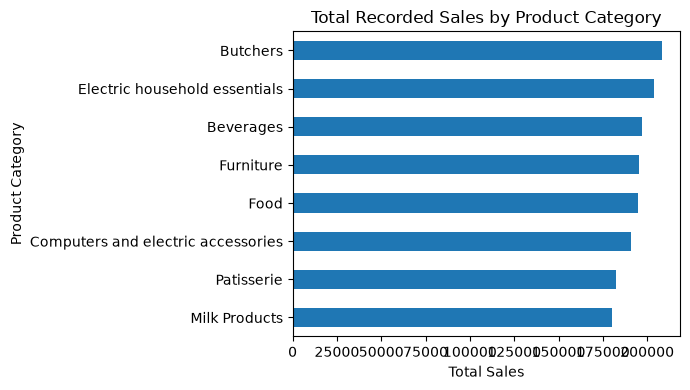

In [40]:
#visualize category sales using matplotlib
plt.figure(figsize=(7, 4))

category_sales.sort_values().plot(kind="barh")

plt.title("Total Recorded Sales by Product Category")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")

plt.ticklabel_format(axis="x", style="plain")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
#analyze monthly sales trends
monthly_sales = (
    df_clean.groupby(df_clean["Transaction Date"].dt.to_period("M"))["Total Spent"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

print("Top 5 months by sales:")
print(monthly_sales.sort_values(ascending=False).head(5))

Top 5 months by sales:
Transaction Date
2022-01    52911.5
2024-12    48466.5
2023-01    48052.5
2024-01    47908.5
2024-04    46271.0
Name: Total Spent, dtype: float64


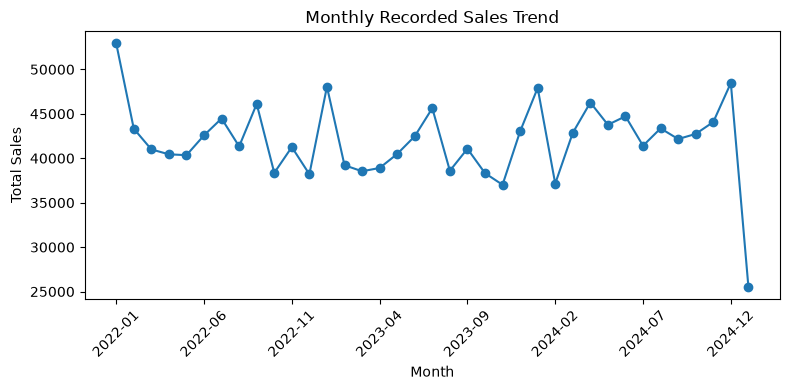

In [42]:
plt.figure(figsize=(8, 4))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Recorded Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [43]:
#analyze payments methods
payment_sales = (
    df_clean.groupby("Payment Method")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

print(payment_sales)

Payment Method
Cash              537710.0
Digital Wallet    507279.0
Credit Card       507082.0
Name: Total Spent, dtype: float64


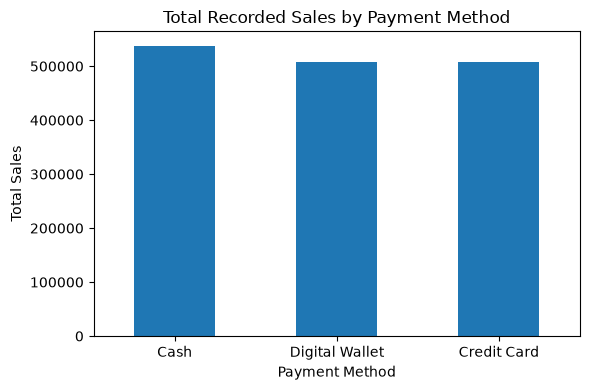

In [44]:
#creating a chart for the above
plt.figure(figsize=(6, 4))

payment_sales.plot(kind="bar")

plt.title("Total Recorded Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Conclusion
This project analysed retail transaction data using Python, Pandas and Matplotlib. The dataset was inspected and cleaned by investigating missing values, checking for duplicates, validating sales totals and converting transaction dates into datetime format.

The analysis found that the Butchers category had the highest recorded sales, while Milk Products had the lowest. Cash transactions contributed the most recorded sales among the three payment methods. Monthly sales fluctuated across the period, with a particularly sharp drop in December 2024 that requires further investigation.

Overall, the project demonstrates how data cleaning and exploratory data analysis can help identify sales patterns and support data-driven business decisions. The findings describe recorded sales rather than profit and the conclusions are subject to the dataset's missing values and other limitations.